# Spatial hashing with a Morton encoding hash function

Spatial hashing is a multidimensional search algorithm that is used to quickly locate elements or faces in a mesh that a point in space resides within. Unlike KDTree, BallTree, Quad/Octree based search methods, Spatial hashing is O(1) complexity with respect to the number of elements or faces in a mesh.

## Motivation
One naive way to find the face that a point resides within is to minimize the distance between the query point and each face center. To do this, you can use the corner vertices of each face to first compute the center of each face. Next, we can calculate the distance from the query point to each face center. A sorting algorithm can then be applied to find the face whose centroid is nearest the query point. Distance minimization, while quick, does not gaurantee a point is within the cell, but provides a good starting guess for a follow-up search.

The main issue with this approach is that searching across the entire mesh can be quite expensive. Additionally, the cost of the distance calculation alone scales linearly with the number of faces. Spatial hashing aims to locate a small number of faces that are good candidates for searching. This is done by grouping faces that are within close proximity to each other into "bins". Often, the bounding boxes or face centroids are "hashed" to compute a bin ID to sort each face into. When querying which face a point resides in, it's position too is hashed to determine which bin to look within. Ideally, the number of faces within each bin is small. This way, when we're performing distance minimization (or some other point-in-cell check), it's done only over a small number of faces, rather than the whole mesh.

When designing a spatial hashing function, there are a few key ingredients :
* Hashing function - converts spatial positions to integer hash id's
* Face binning function - the method to determine which bins a face belongs to
* Point-in-cell check - a function that provides yes/no check of whether a query point is in the cell

## Hashing with Morton Encoding
Here, we consider Morton encoding as the hashing function. Morton encoding is commonly used by groups that work with unstructured grids to order elements along space filling curves. By traversing a mesh in order of increasing morton code number, you follow a tightly wound path that connects neighboring elements. When elements are ordered according to their morton number, domain decomposition of $N$ elements into $P$ groups based off this 1-D ordering is quite trivial and provides reasonable strong scaling. 

In our case, we take advantage of the fact that a Morton encoding of a physical position provides a quick method for converting 2-D and 3-D positions into a single integer. Morton encoding involves two main steps

1. Quantization of each spatial dimension to spatial indices $(z,y,x) \rightarrow (z_i, y_i, x_i)$
2. Bit interleaving to convert the spatial indices to the morton code $(z_i, y_i, x_i) \rightarrow m_i$

For spatial hashing, the quantization is equivalent to creating a "hash grid". Bit interleaving simply serves the purpose of creating a single integer "bin" (or "hash id") to associate a position with.

### Quantization
Quantization is simply the process of converting continuous data into a finite amount of information. In our case, we're converting the position in each physical dimension to an integer. Suppose that $x \in [x_{min},x_{max}]$. This can be normalized to the range $[0,1]$ and multiplied by an integer $B_w$ to obtain a value in the range $[0,B_w]$. When stored as an integer, effectively applying a "floor" function we get $B_w+1$ discrete integers that each position can be sorted into. In some sense, you can look at quantization as "coarse-graining" a range of floating point values.

Let's look at an example.

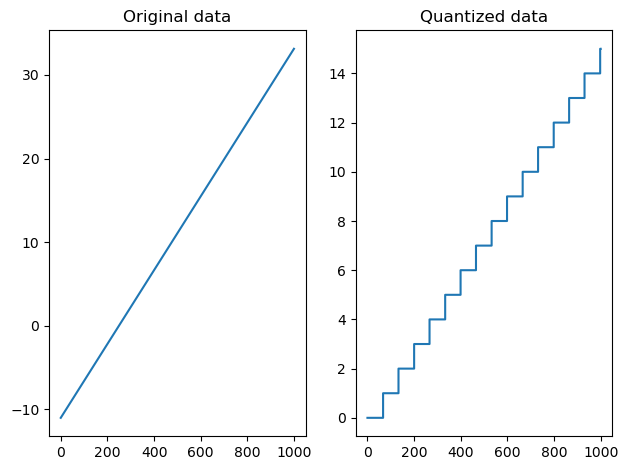

In [16]:
import numpy as np
def quantize(x,bw,xmin,xmax):
    """Quantize the input array x to integers in the range [0,bw] based on the bounds xmin, xmax."""
    xq = np.floor((x - xmin) / (xmax - xmin) * bw).astype(np.int64)
    xq = np.clip(xq, 0, bw)  # Ensure values are within [0, bw]
    return xq


x = np.linspace(-11.0, 33.12, 1000)

xi = quantize(x, 15, -11.0, 33.0)

import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.plot(x)
ax1.set_title("Original data")
ax2.plot(xi, drawstyle='steps-post')
ax2.set_title("Quantized data")
fig.tight_layout()
plt.show()


In the above example, we (seemingly) arbitrarily chose $B_w=15$. With $B_w=15$ there are 16 possible values a quantized position can have $x_i = [0,15]$. Increasing $B_w$ increases the number of possible bins to search in. Let's take a look at a few different values of $B_w$ (bit width)

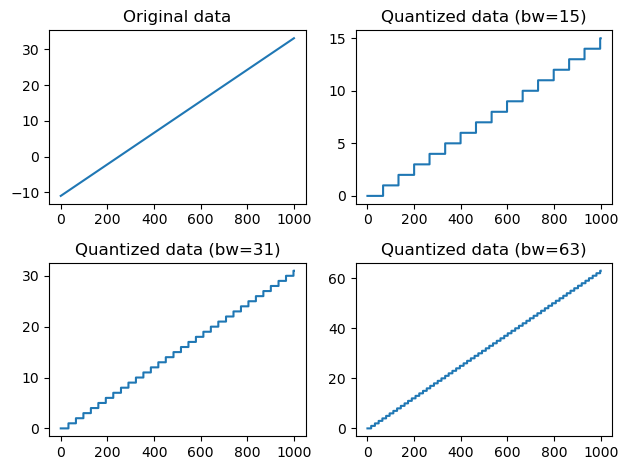

In [17]:
xi31 = quantize(x, 31, -11.0, 33.0)
xi63 = quantize(x, 63, -11.0, 33.0)

fig, axs = plt.subplots(2, 2)
axs[0, 0].plot(x)
axs[0, 0].set_title("Original data")
axs[0, 1].plot(xi, drawstyle='steps-post')
axs[0, 1].set_title("Quantized data (bw=15)")
axs[1, 0].plot(xi31, drawstyle='steps-post')
axs[1, 0].set_title("Quantized data (bw=31)")
axs[1, 1].plot(xi63, drawstyle='steps-post')
axs[1, 1].set_title("Quantized data (bw=63)")
fig.tight_layout()
plt.show()

By increasing the bit width, we increase the number of possible quantized states. The tradeoff is in the number of "source" grid points that are assigned to each bin (this metric is called the **hit count**). To see this, we'll look at plots of the number of repeated spatial indices as a function of the unique hash indices for each quantization

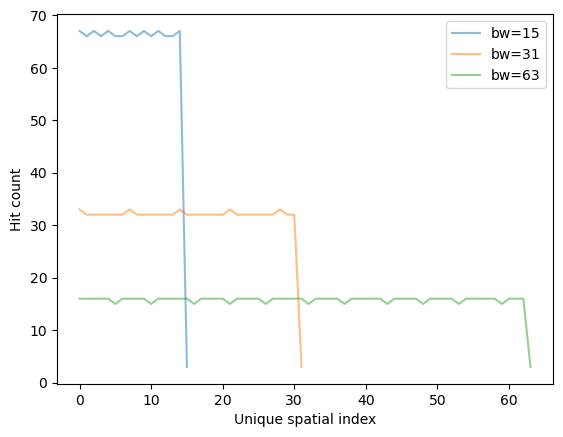

In [23]:
keys, starts, counts = np.unique(xi, return_index=True, return_counts=True)
keys31, starts, counts31 = np.unique(xi31, return_index=True, return_counts=True)
keys63, starts, counts63 = np.unique(xi63, return_index=True, return_counts=True)


plt.plot(keys,counts, label='bw=15', alpha=0.5)
plt.plot(keys31,counts31, label='bw=31', alpha=0.5)
plt.plot(keys63,counts63, label='bw=63', alpha=0.5)
plt.xlabel('Unique spatial index')
plt.ylabel('Hit count')
plt.legend()


In the context of spatial searching, the lower bit width results in more faces for each "bin", which may not be ideal. Higher bit width results in fewer faces for each bin; when performing spatial queries having fewer faces to check for expensive "point-in-cell" or "distance minimization" is ideal.



#### Determining Bit Width
So far, we've been a bit vague in terms of what is "low" bit width and what is "high bit width". In the example above, the spatial positions are represented by an array with 1000 values. Quantizing to a bit width of 1000 or greater (for this trivial uniformly spaced grid) could potentially return exactly 1 face per spatial index. 

Depending on how exactly the minimum and maximum extents of the quantization function (`xmin` and `xmax`) are set, it's possible for some spatial indices to not be associated with any points, and for some to have more than one. In the example below, we change the extent of the quantization domain to match the min and max extents of the source grid. Additionally, we look at the hit counts for bit widths of 511, 1000, and 1023.


Text(0, 0.5, 'Hit count')

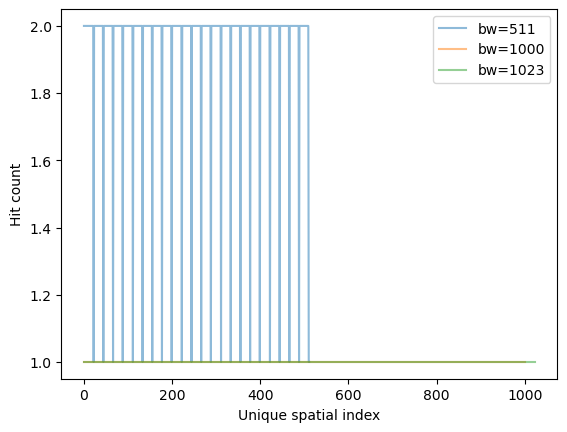

In [37]:
xi511 = quantize(x, 511, -11.0, 33.12)
keys511, starts, counts511 = np.unique(xi511, return_index=True, return_counts=True)

xi1000 = quantize(x, 1000, -11.0, 33.12)
keys1000, starts, counts1000 = np.unique(xi1000, return_index=True, return_counts=True)

xi1023 = quantize(x, 1023, -11.0, 33.12)
keys1023, starts, counts1023 = np.unique(xi1023, return_index=True, return_counts=True)

plt.plot(keys511,counts511, label='bw=511', alpha=0.5)
plt.plot(keys1000,counts1000, label='bw=1000', alpha=0.5)
plt.plot(keys1023,counts1023, label='bw=1023', alpha=0.5)
plt.legend()
plt.xlabel('Unique spatial index')
plt.ylabel('Hit count')

In the above example, for a bit width of 512, there are between 1 and 2 hits per spatial index. At bit widths of 1000 and 1023, each spatial index is associated with exactly 1 face. Effectively, the "resolution" of the hash grid is as fine or finer than the source grid for bit widths of 1000 and 1023.

Now, what happens if the domain extent used for the quantization does not match the min and max range of the source grid ? Below, we look at a scenario with bit width of 1023, but change the domain extent used for quantization to be much larger than the domain extent of the data. For reference, in this example, $x \in [-11.0, 33.12]$ and here we choose the quantization domain to be $[-20.0, 40]$. 

Intuitively, we might expect that increasing the quantization domain extent and keeping the number of quantization values fixed effectively coarsens the hash grid. Additionally, because there are cells in the hash grid that are beyond the extent of the parent grid, some of the hash cells will have a hit count of 0.

Text(0, 0.5, 'Hit count')

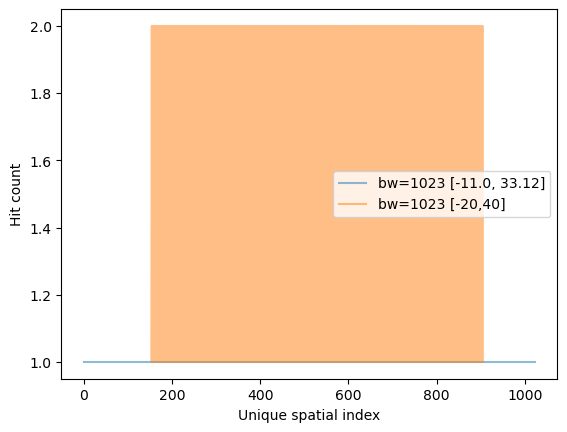

In [39]:
xi1023_lrg = quantize(x, 1023, -20.0, 40)
keys1023_lrg, starts, counts1023_lrg= np.unique(xi1023_lrg, return_index=True, return_counts=True)

plt.plot(keys1023,counts1023, label='bw=1023 [-11.0, 33.12]', alpha=0.5)
plt.plot(keys1023_lrg,counts1023_lrg, label='bw=1023 [-20,40]', alpha=0.5)
plt.legend()
plt.xlabel('Unique spatial index')
plt.ylabel('Hit count')

The above figure confirms our intuition. When we increase the extent of the quantization domain, the hash grid is effectively coarsened; this is consistent with using seeing between 1 and 2 hits for each spatial index (instead of seeing 1 across the board). Additionally, on the left and right ends of the quantization domain, the hit count is identically zero.

#### Effects of variable resolution in the source grid
Work in progress

#### Summary of Quantization
To summarize this section on quantization, we're left with the following observations :
* The bit width and quantization domain extent together are equivalent to defining a hash grid
* Quantization domain extents that are beyond the extent of the source grid result in some spatial indices having no hit counts.
* High bit widths generally result in more resolution and lower hit counts per spatial index
* Low bit widths generally result in less resolution and higher hit counts per spatial index

Up to this point, we've only considered mapping single points to spatial indices. In other words, our **face binning function** maps a face to a hash bin based on the quantization of its left grid cell. When determining if a query point resides within a cell, 

## Bit interleaving
For the purpose of multidimensional spatial hashing, morton encoding of spatial positions involves quantizing each component of a position vector into spatial indices. Bit interleaving is a clean and fast method to uniquely map two or three indices (E.g. `(zi,yi,xi)`) to a single index (`mi`) that we call the "morton code". In the context of spatial hashing, developing a hash function that is fast and avoids collisions (two different spatial index sets mapping to the same `mi`) is critical. 

Up to this point, the only constraints on the bit width that we've considered have been related to resolution considerations. When using bit interleaving, we need to be cognizant of the range of values that can be represented by standard integer representations (e.g. `uint32` or `uint64`). Suppose, for a moment, that each spatial index is stored as a `uint32` data type. If we can gaurantee, for example, that each `zi`,`yi`,`xi` are between $[0,1023]$ they can functionally be represented by an unsigned 10-bit integer without loss. As we've seen previously, we can gaurantee this by choosing the bit width for the quantization. Then, imagine combining the first 10 bits of each `zi`,`yi`,`xi` in some way to create a new `uint32` number.




![xi yi zi stored as uint32 with bit width of 1023](xiyizi.png)

In the picture above we see a schematic depicting the "bits" of `xi`, `yi` and `zi`. The colored "bits" are the first ten "active" bits. The remaining gray bits are all zero, since, in this example, we're assuming a quantization bit width of 1023 for each spatial index. A common bit interleaving strategy is take two bits from `xi` and append two bits from `yi` and then two bits from `zi` and repeat this pattern until all 10 bits from each spatial index are exhausted. The last two bits for the Morton code (which is stored as a `uint32`) are set to 0. The image below shows the resulting bit representation of the Morton code.

![mi stored as uint32 with bit width of 1023 with 2-bit interleaving](mi.png)

The number of bits to interleave with (the interleave depth) has more impact on domain decomposition problems than it does for spatial hashing. Essentially, the interleave depth determines how large subdomains are traversed by space filling curves. [This paper](https://people.ece.ubc.ca/leos/pdf/ref/SchrackStocco2015.pdf) is a good read on this. For our purposes, we primarily care about each `(zi,yi,xi)` combination mapping to a unique integer for the hash table to avoid hash table collisions.

In practice, bit interleaving is performed by "dilating" the bits of each spatial index, shifting the bits for `yi` and `zi`, and merging bits to obtain a new `uint32` number. Bit dilation essentially adds 0 bits in a regular pattern.

![schematic of bit interleaving by bit dilation and bit shifting](dilate_bitshift.png)

Now that we have a conceptual idea for how to do this, let's look at how to implement this in practice.